## ToDo:

- write function that creates a space-time-blanket
- will it replace the current method? will it be an addition?
- come up with use examples (gauss, spatial trend, epicenter, ...)
- different modes for temporal shift or itensity shift?
- write tests
- add tutorial

In [1]:
import numpy as np
from ponds import PONDS, ELLIPSIS

pd = PONDS(
    lat_size=21,
    lon_size=21,
    time_size=20,
)

b1 = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=50,
    ecc_lon=50,
)

mask1 = b1.make_shape(
    lats=pd.lats,
    lons=pd.lons
)

shift_time1 = np.random.rand(*mask1.shape)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm

def barplot_3D(
        mask,
        pd,
        time_values,
        alpha=1.0,
        tick_number=5,
        cmap="viridis",
    ):
    """
    Create an interactive 3D bar plot of values on a masked grid.
    Bars are colored based on their height using a colormap.
    """

    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection="3d")

    # Create grid
    x, y = np.meshgrid(pd.lons, pd.lats)
    dx = np.abs(pd.lons[1] - pd.lons[0])
    dy = np.abs(pd.lats[1] - pd.lats[0])

    # Normalize values to [0,1] for colormap
    norm = plt.Normalize(time_values[mask].min(), time_values[mask].max())
    colors = plt.colormaps[cmap](norm(time_values[mask]))  # updated line

    # Plot bars with color-mapped heights
    ax.bar3d(
        x[mask],
        y[mask],
        np.zeros_like(time_values[mask]),
        dx,
        dy,
        time_values[mask],
        zsort="average",
        alpha=alpha,
        color=colors,
        edgecolor="black",
    )

    # Custom ticks
    ax.set_xticks(pd.lons[::max(1, len(pd.lons)//tick_number)])
    ax.set_yticks(pd.lats[::max(1, len(pd.lats)//tick_number)])
    ax.grid(True)

    # Axis limits and labels
    ax.set_xlim(pd.lons.min(), pd.lons.max())
    ax.set_ylim(pd.lats.min(), pd.lats.max())
    ax.set_zlim(0, time_values.max() * 1.1)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_zlabel("Shift Time")

    # Add a colorbar
    mappable = cm.ScalarMappable(cmap=plt.colormaps[cmap], norm=norm)
    mappable.set_array([])
    fig.colorbar(mappable, ax=ax, shrink=0.5, aspect=10, pad=0.1, label="Shift Time")

    return fig, ax


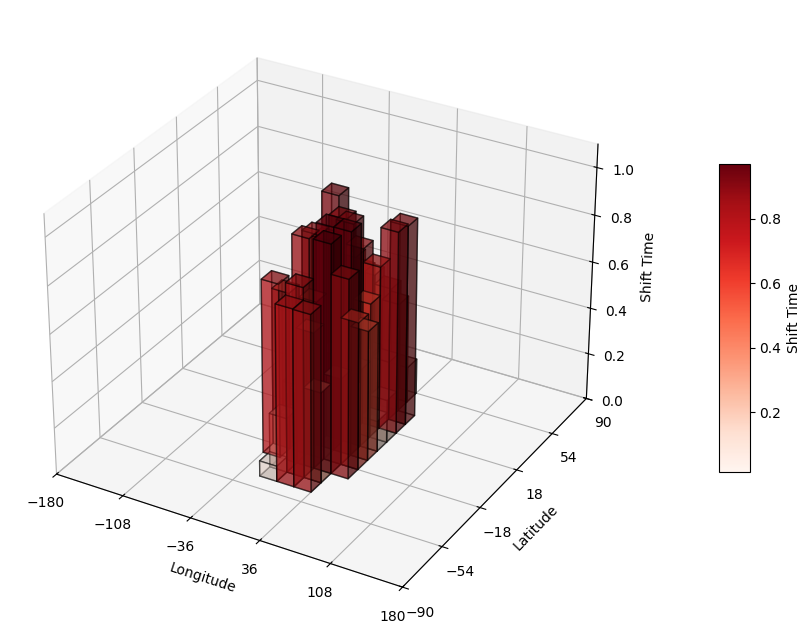

In [3]:
# Use an interactive backend inside Jupyter
%matplotlib inline

fig, ax = barplot_3D(
    mask1,
    pd,
    shift_time1,
    alpha=0.5,
    cmap="Reds",
    )


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

%matplotlib inline
from IPython.display import HTML


def rotating_barplot_3D(
        mask,
        pd,
        time_values,
        alpha=1.0,
        tick_number=5,
        cmap="viridis",
    ):
    """
    Create a continuously rotating 3D bar plot of values on a masked grid.
    """

    fig, ax = barplot_3D(
        mask,
        pd,
        time_values,
        alpha=alpha,
        tick_number=tick_number,
        cmap=cmap,
    )

    # Animation function (keeps increasing azimuth)
    def update(frame):
        ax.view_init(elev=30, azim=frame)
        return fig,

    anim = FuncAnimation(
        fig, update, frames=np.arange(0, 360, 15), interval=100, repeat=True
    )
    plt.close(fig)

    
    return HTML(anim.to_jshtml())



In [5]:
rotating_barplot_3D(
    mask1,
    pd,
    shift_time1,
    alpha=0.5,
    cmap="Reds",
    )


In [6]:
import numpy as np
from scipy.stats import multivariate_normal

def gauss_time(
        pd,
        center_lat=0,
        center_lon=0,
        sigma_lat=10,
        sigma_lon=10,
):
    """
    ...
    """

    extended_lons = np.concatenate([pd.lons - 360, pd.lons, pd.lons + 360])

    # Create grids
    lat_grid, extended_lon_grid = np.meshgrid(pd.lats, extended_lons, indexing="ij")
    pos_extended = np.dstack((lat_grid, extended_lon_grid))

    # Calculate Gaussian blob
    cov = np.array([[sigma_lat**2, 0], [0, sigma_lon**2]])
    rv = multivariate_normal(mean=[center_lat, center_lon], cov=cov)
    extended_blob = rv.pdf(pos_extended)
    blob_normalized = extended_blob / np.max(extended_blob)


    # Apply shift to data
    shift_time = np.zeros((len(pd.lats), len(pd.lons)))
    for i in range(len(pd.lats)):
        for j in range(len(pd.lons)):
            # Sum contributions from periodic longitudes
            blob_contribution = np.sum(
                [blob_normalized[i, j + k * len(pd.lons)] for k in range(3)],
            )
            shift_time[i, j] = blob_contribution

    return shift_time

In [12]:
from ponds import PONDS, ELLIPSIS

pd = PONDS(
    lat_size=51,
    lon_size=51,
    time_size=20,
)

b2 = ELLIPSIS(
    center_lat=0,
    center_lon=0,
    ecc_lat=50,
    ecc_lon=50,
)

mask2 = b2.make_shape(
    lats=pd.lats,
    lons=pd.lons
)

shift_time2 = gauss_time(
    pd,
    center_lat=20,
    center_lon=20,
    sigma_lat=50,
    sigma_lon=50
)

# Use an interactive backend inside Jupyter
%matplotlib inline

rotating_barplot_3D(
    mask2,
    pd,
    shift_time2,
    alpha=0.5,
    cmap="Reds",
    )

